# Comparis Listings: Data Cleaning

Cleans the Comparis scrape in `data/raw/comparis.db` (Apify export, 26–29 Oct 2026) and writes
`data/interim/comparis_cleaned.db`. The raw file is opened read-only. All logic lives in
`rentml.comparis` and in the shared pipeline functions of `rentml.data` / `rentml.geo`, so the
rental objects are cleaned exactly like the DSPRO1 listings.

| Table in `comparis_cleaned.db` | Content |
|---|---|
| `listings` | every raw listing, typed and anonymised, with feature flags, `object_id` and `drop_reason` |
| `rent` | one row per plausible rental object (monthly net rent), admin units, `rent_regime`, `ppsqm_outlier` |
| `duplicate_links` | listing pairs linked as the same object and the rule that linked them |
| `cleaning_log` | rows per cleaning step |
| `meta` | raw file checksum, creation time, row counts |

> **Data use.** `docs/DATENBESCHAFFUNG.md` lists comparis.ch and the SMG portals (homegate,
> ImmoScout24) as sources whose terms forbid systematic reading. Keep both databases local
> (`data/raw/`, `data/interim/` are git-ignored) and settle the permitted use before the data
> enter models, figures or the app.

## 1. Setup

In [1]:
import logging
import sqlite3
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm import in a dependency

In [2]:
from rentml import comparis, data, geo, text
from rentml.evaluation import COLORS, apply_plot_style

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
apply_plot_style()

RAW_DB, CLEANED_DB = comparis.RAW_DB, comparis.CLEANED_DB
print(f"raw: {RAW_DB} ({RAW_DB.stat().st_size / 1e6:,.0f} MB) -> cleaned: {CLEANED_DB}")

raw: /home/sa_linux/code/Elias-Martinelli/dspro2/data/raw/comparis.db (545 MB) -> cleaned: /home/sa_linux/code/Elias-Martinelli/dspro2/data/interim/comparis_cleaned.db


## 2. Raw Data

One row per Comparis listing id. Comparis aggregates partner portals, so the same flat can appear
under several ids (section 6). `price_type` comes from `raw_json`; it separates monthly rents from
weekly, daily and yearly prices.

In [3]:
raw = comparis.load_raw(RAW_DB)
print(
    f"{len(raw):,} listings, scraped {raw['scraped_at'].min()[:10]} "
    f"to {raw['scraped_at'].max()[:10]}"
)
display(pd.crosstab(raw["property_type"], raw["deal_type"], margins=True))
display(pd.crosstab(raw["price_type"], raw["deal_type"]))
display(raw["partner"].value_counts().head(12).rename("listings").to_frame().T)

INFO rentml.comparis: Read 65552 raw listings from /home/sa_linux/code/Elias-Martinelli/dspro2/data/raw/comparis.db


65,552 listings, scraped 2026-10-26 to 2026-10-29


deal_type,buy,rent,All
property_type,,,
Attika,1250,352,1602
Bauernhaus,241,19,260
Dachwohnung,1120,943,2063
Doppeleinfamilienhaus,1313,124,1437
Einzelzimmer,4,772,776
Haus,10858,1174,12032
Loft,197,154,351
Maisonette,907,709,1616
Reihenhaus,879,99,978


deal_type,buy,rent
price_type,,
Jährlicher Mietpreis pro m²,0,1
Kaufpreis,39671,0
Kaufpreis pro m²,2,0
Mietpreis pro Jahr,0,13
Mietpreis pro Monat,0,25668
Mietpreis pro Tag,0,21
Mietpreis pro Woche,0,174
Monatlicher Mietpreis pro m²,0,2


partner,immobilier.ch,immoscout24.ch,homegate.ch,Properstar,UrbanHome.ch,RealAdvisor,Comparis,Flatfox,Neho,smart-propylaia.com,betterhomes.ch,Properti
listings,12239,10697,9064,8503,7269,2986,2182,1447,864,635,574,539


In [4]:
numeric = [
    "price",
    "price_net",
    "side_costs",
    "rooms",
    "living_area",
    "year_built",
    "renovation_year",
    "balcony_count",
]
rent_raw = raw[raw["deal_type"].eq("rent")]
summary = rent_raw[numeric].describe(percentiles=[0.01, 0.5, 0.99]).T
summary["missing_pct"] = 100 * rent_raw[numeric].isna().mean()
summary["zero_pct"] = 100 * rent_raw[numeric].eq(0).mean()
display(
    summary.round(1)
)  # rentals only: 0 years, 999 rooms and 2.4 M rents are placeholders/errors

,count,mean,std,min,1%,50%,99%,max,missing_pct,zero_pct
price,25644.0,2660.2,21522.1,-400.0,450.0,1865.5,10928.2,2440000.0,0.9,0.0
price_net,25643.0,2504.7,21468.0,1.0,400.0,1700.0,10833.0,2440000.0,0.9,0.0
side_costs,15327.0,260.7,2023.0,1.0,60.0,230.0,600.0,250240.0,40.8,0.0
rooms,24683.0,3.6,6.5,-4.5,1.0,3.5,7.6,999.0,4.6,0.0
living_area,19836.0,93.8,83.4,1.0,14.0,85.0,300.0,7000.0,23.4,0.0
year_built,25879.0,664.0,939.7,0.0,0.0,0.0,2026.0,9999.0,0.0,66.6
renovation_year,25879.0,327.6,744.4,0.0,0.0,0.0,2026.0,2029.0,0.0,83.8
balcony_count,25879.0,1.2,136.8,0.0,0.0,0.0,1.0,22001.0,0.0,67.8


## 3. Normalise

`comparis.normalise` keeps every row and applies these rules:

- **Rent:** `price` = net rent (`price_net`), `gross_rent` = `price`, `aux_costs` = `side_costs`.
  Without stated auxiliary costs, net and gross are identical in the data and cannot be told apart
  (`aux_costs_known = False`); the DSPRO1 warning about gross rents applies.
- **Placeholders to NaN:** year 0/9999, areas of "1 m²", rooms outside 1–15 (`rooms_invalid`),
  more than 10 balconies, coordinates outside Switzerland.
- **Parsing:** floor labels ("EG", "3. Stock"), availability ("sofort", "nach Vereinbarung", dates),
  LV95 coordinates (`east`, `north`) from WGS84.
- **Anonymisation:** titles and descriptions go through `text.anonymize_series` (contacts and every
  amount replaced, so the text cannot leak the rent). About a minute for all texts.
- **Features:** `Has*`/`Is*` flags of the portal become 0/1 columns; distances are parsed to metres.

In [5]:
listings = comparis.normalise(raw).join(comparis.expand_features(raw))
replaced = pd.DataFrame(
    {
        "year_built (1000-2031)": [
            (raw["year_built"].fillna(0) > 0).sum(),
            listings["year_built"].notna().sum(),
        ],
        "living_area": [raw["living_area"].notna().sum(), listings["area"].notna().sum()],
        "rooms": [raw["rooms"].notna().sum(), listings["rooms"].notna().sum()],
        "coordinates": [raw["latitude"].notna().sum(), listings["east"].notna().sum()],
        "floor": [raw["floor"].ne("nicht verfügbar").sum(), listings["floor"].notna().sum()],
    },
    index=["raw non-missing", "cleaned non-missing"],
).T
display(replaced)
display(listings["available_label"].value_counts().rename("availability").to_frame().T)
rent_rows = listings["deal_type"].eq("rent")
print(
    "rentals with separate auxiliary costs: "
    f"{listings.loc[rent_rows, 'aux_costs_known'].mean():.1%}"
)
print(f"descriptions with text: {listings['description'].notna().mean():.1%}")

INFO rentml.comparis: normalise: 65552 listings, 249 invalid room counts


,raw non-missing,cleaned non-missing
year_built (1000-2031),37989,37982
living_area,52349,52337
rooms,62578,62327
coordinates,65552,65550
floor,42127,42127


available_label,by_arrangement,immediately,date
availability,36858,19755,8939


rentals with separate auxiliary costs: 59.2%
descriptions with text: 91.4%


## 4. Coordinate Precision

Many listings carry the coordinate of their municipality or postcode rather than of the building
(e.g. one point in Lugano with listings from several streets). Such points would merge different
flats as duplicates and would give wrong hectare-level features (noise, ÖV, QoLI). They are kept
but flagged (`coord_precise = False`); the admin assignment still works for them.

In [6]:
precision = listings.groupby("deal_type")["coord_precise"].mean().rename("precise share")
display(precision.to_frame().T.round(3))
centroids = (
    listings[~listings["coord_precise"]]
    .groupby(["east", "north"])
    .agg(listings=("city", "size"), streets=("coord_streets", "first"), city=("city", "first"))
    .sort_values("listings", ascending=False)
)
display(centroids.head(8))

deal_type,buy,rent
precise share,0.568,0.848


,,listings,streets,city
east,north,,,
2.605348e+06,1.133919e+06,556,47,Crans-Montana
2.717124e+06,1.096441e+06,541,11,Lugano
2.563161e+06,1.141920e+06,247,24,Montreux
2.593417e+06,1.119512e+06,219,16,Sitten
2.503240e+06,1.118639e+06,164,6,Cologny
2.579514e+06,1.108531e+06,154,12,Saxon
2.591983e+06,1.246234e+06,140,9,Delsberg
2.608037e+06,1.126700e+06,140,19,Sierre


## 5. Rental Scope

The rental analysis keeps rentals with a monthly price and coordinates. Sales stay in `listings`
(`drop_reason = deal_type_buy`) for a later analysis of purchase prices.

In [7]:
scope = comparis.rent_scope(listings)
display(scope.fillna("in scope").value_counts().rename("listings").to_frame().T)
rent = listings[scope.isna()]

,deal_type_buy,in scope,price_not_monthly,coordinates_missing
listings,39673,25666,211,2


## 6. Duplicates

`data.link_duplicates` (same rules as the ML pipeline) on `comparis.linking_frame`: centroid
coordinates and addresses without a house number are not used, and a shared description only links
listings with the same rooms and area bucket, because managers reuse one text for every flat of a
new building. Linked listings form one object (connected components); the object keeps the
smallest listing id and the median rent.

In [8]:
link_frame = comparis.linking_frame(rent)
links = data.link_duplicates(link_frame)
object_ids = data.assign_object_ids(link_frame, links)
display(data.dedup_report(rent, object_ids, links).round(3).to_frame().T)

partners = rent.assign(object_id=object_ids).groupby("object_id")["partner"].nunique()
print(f"objects on several partner portals: {(partners > 1).sum():,}")
objects = data.collapse_objects(rent, object_ids)
print(f"{len(rent):,} listings -> {len(objects):,} objects")

INFO rentml.data: 25666 listings -> 23249 objects


,rows,unique_objects,duplicate_rows,duplicate_share_pct,objects_with_duplicates,objects_size_2,objects_size_3,objects_size_4plus,max_group_size,median_rel_price_range_dup_objects,links_coords,links_description,links_address,links_exact
value,25666.0,23249.0,2417.0,9.417,2017.0,1777.0,166.0,74.0,14.0,0.0,1972.0,1728.0,1696.0,1002.0


objects on several partner portals: 1,638
25,666 listings -> 23,249 objects


## 7. Municipalities, Districts, Cantons

swissBOUNDARIES3D (cached in `data/external/`). Points in Liechtenstein, Büsingen and Campione are
excluded; points within 2 km of a border or lake are snapped to the nearest municipality.

In [9]:
gpkg = geo.download_swissboundaries()
units = geo.load_admin_units(gpkg)
objects = geo.assign_admin_units(objects, units, exclude=geo.load_foreign_mask(gpkg))
display(objects["admin_match"].value_counts().rename("objects").to_frame().T)
matched = objects[objects["admin_match"].ne("none")]

INFO rentml.geo: Admin assignment: {'within': 23249}


admin_match,within
objects,23249


## 8. Domain Rules, CHF/m² Outliers and Rent Regime

- `data.domain_filter`: area 10–500 m², net rent CHF 300–15'000, rooms 1–15 (removes parking
  spaces, storage rooms and the 2.4 M "rents" that are sale prices).
- `data.price_per_sqm_outliers`: robust z-score of log CHF/m² within municipality → district →
  canton. **Flagged, not removed** (`ppsqm_outlier`), so the analysis can decide.
- `rent_regime`: rule-based text extraction (cooperative, subsidised, shared flat); single rooms
  (`Einzelzimmer`) and the portal flag `is_flat_share` count as `shared_flat`.

In [10]:
kept, removed_domain = data.domain_filter(matched)
display(removed_domain["reason"].value_counts().rename("objects").to_frame().T)

kept = kept.assign(ppsqm_outlier=data.price_per_sqm_outliers(kept))
regime = text.extract_frame(kept["description"], text.rule_based_extract)["rent_regime"]
shared = kept["property_category"].eq("room") | kept["is_flat_share"].eq(1)
kept["rent_regime"] = regime.fillna("unknown").mask(shared, "shared_flat")
display(
    kept.assign(chf_m2=kept["price"] / kept["area"])
    .groupby("rent_regime")
    .agg(
        objects=("price", "size"),
        median_rent=("price", "median"),
        median_chf_m2=("chf_m2", "median"),
    )
    .round(1)
)
print(f"CHF/m² outliers flagged: {kept['ppsqm_outlier'].sum():,} of {len(kept):,}")

INFO rentml.data: domain_filter: removed {'area_missing': 5642, 'price_missing': 95, 'area_above_max': 39, 'price_below_min': 32, 'price_above_max': 32, 'area_below_min': 12}


reason,area_missing,price_missing,area_above_max,price_below_min,price_above_max,area_below_min
objects,5642,95,39,32,32,12


INFO rentml.data: price_per_sqm_outliers: 497 of 17397 flagged


,objects,median_rent,median_chf_m2
rent_regime,,,
cooperative,56,1590.0,19.7
cost_based_or_subsidised,7,2070.0,20.5
market,16846,1750.0,21.3
shared_flat,488,940.0,49.1


CHF/m² outliers flagged: 497 of 17,397


## 9. Comparison with the DSPRO1 Data

The DSPRO1 snapshot (rentumo, April 2026, `data/dspro1_snapshot/`) through the same domain filter,
against the Comparis market-rent apartments (no outliers). Differences in rent level reflect both
the six months between the scrapes and the different portals and regions covered. DSPRO1 stored
whole rooms (3.5 became 4), hence no half rooms there.

In [11]:
dspro1, _ = data.load_listings("csv")
dspro1 = geo.assign_admin_units(data.fix_schema(dspro1), units, exclude=geo.load_foreign_mask(gpkg))
dspro1, _ = data.domain_filter(dspro1[dspro1["admin_match"].ne("none")])
market = kept[
    kept["rent_regime"].isin(["market", "unknown"])
    & ~kept["ppsqm_outlier"]
    & kept["property_category"].eq("apartment")
]


def profile(df: pd.DataFrame) -> dict[str, float]:
    chf_m2 = df["price"] / df["area"]
    return {
        "objects": len(df),
        "median rent": df["price"].median(),
        "median area": df["area"].median(),
        "median CHF/m²": chf_m2.median(),
        "half rooms": (df["rooms"] % 1 == 0.5).mean(),
        "with description": df["description"].notna().mean(),
        "municipalities": df["municipality_id"].nunique(),
    }


display(pd.DataFrame({"DSPRO1 (rentumo)": profile(dspro1), "Comparis": profile(market)}).round(2))
cantons = pd.DataFrame(
    {
        "DSPRO1": dspro1["canton"].value_counts(normalize=True),
        "Comparis": market["canton"].value_counts(normalize=True),
    }
).fillna(0)
display((100 * cantons).round(1).sort_values("Comparis", ascending=False).T)

INFO rentml.data: Loaded 9405 listings from the CSV snapshot /home/sa_linux/code/Elias-Martinelli/dspro2/data/dspro1_snapshot


INFO rentml.data: fix_schema: 1 implausible room counts set to NaN


INFO rentml.geo: Admin assignment: {'within': 9391, 'none': 14}


INFO rentml.data: domain_filter: removed {'area_above_max': 5, 'price_above_max': 2}


,DSPRO1 (rentumo),Comparis
objects,9384.00,15582.00
median rent,1600.00,1710.50
median area,76.00,83.00
median CHF/m²,21.72,21.22
half rooms,0.00,0.70
with description,0.00,1.00
municipalities,1186.00,1493.00


canton,ZH,TI,VD,BE,AG,SG,FR,BL,GE,NE,VS,SO,BS,TG,JU,LU,GR,AR,SH,SZ,ZG,GL,AI,NW,OW,UR
DSPRO1,14.6,7.0,10.5,11.5,6.6,7.2,5.2,4.9,4.2,4.3,3.6,3.3,4.3,3.7,1.8,2.8,1.4,0.7,1.0,0.7,0.2,0.3,0.1,0.1,0.1,0.1
Comparis,12.0,10.4,10.4,9.5,6.7,6.0,5.4,5.4,4.8,4.7,4.3,4.0,3.3,3.1,2.6,2.6,1.4,0.9,0.8,0.8,0.4,0.3,0.1,0.1,0.1,0.1


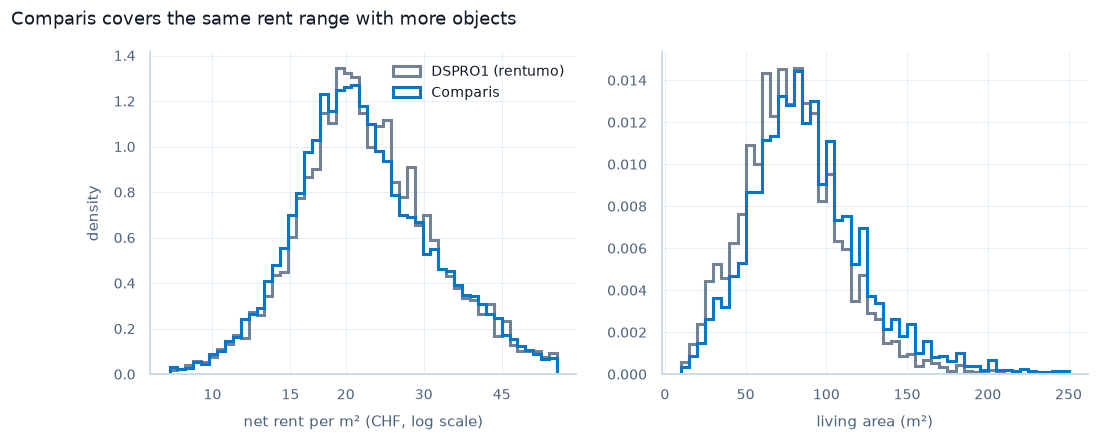

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(np.log(8), np.log(60), 50)
for df, label, color in [
    (dspro1, "DSPRO1 (rentumo)", COLORS["gray"]),
    (market, "Comparis", COLORS["primary"]),
]:
    axes[0].hist(
        np.log(df["price"] / df["area"]),
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        label=label,
        color=color,
    )
    axes[1].hist(
        df["area"],
        bins=np.arange(10, 251, 5),
        density=True,
        histtype="step",
        linewidth=2,
        label=label,
        color=color,
    )
ticks = [10, 15, 20, 30, 45]
axes[0].set_xticks(np.log(ticks), ticks)
axes[0].set(xlabel="net rent per m² (CHF, log scale)", ylabel="density")
axes[1].set(xlabel="living area (m²)")
axes[0].legend(frameon=False)
fig.suptitle("Comparis covers the same rent range with more objects", x=0.01, ha="left")
plt.show()

## 10. Write `comparis_cleaned.db`

`listings.drop_reason` records why a listing is not in `rent`: scope (section 5), `duplicate`
(a further listing of an object), `admin_unmatched` or a domain rule. `object_id` is set for all
rentals in scope.

In [13]:
drop_reason = scope.copy()
drop_reason[object_ids.index[~object_ids.index.isin(objects.index)]] = "duplicate"
drop_reason[objects.index[objects["admin_match"].eq("none")]] = "admin_unmatched"
drop_reason[removed_domain.index] = removed_domain["reason"]
listings_out = listings.assign(object_id=object_ids, drop_reason=drop_reason)
assert listings_out["drop_reason"].isna().sum() == len(kept)

steps = pd.DataFrame(
    [
        ("raw listings", len(raw)),
        ("rentals with monthly price and coordinates", len(rent)),
        ("one row per object (dedup)", len(objects)),
        ("admin match in Switzerland", len(matched)),
        ("domain rules (area, rent, rooms)", len(kept)),
        ("of which market apartments without CHF/m² outlier", len(market)),
    ],
    columns=["step", "n_rows"],
)
steps["removed"] = (-steps["n_rows"].diff()).fillna(0).astype(int)
steps["retained_pct"] = (100 * steps["n_rows"] / len(raw)).round(1)
display(steps)

tables = {"listings": listings_out, "rent": kept, "duplicate_links": links, "cleaning_log": steps}
tables["meta"] = comparis.meta_table(RAW_DB, tables)
comparis.write_db(tables, CLEANED_DB)

,step,n_rows,removed,retained_pct
0,raw listings,65552,0,100.0
1,rentals with monthly price and coordinates,25666,39886,39.2
2,one row per object (dedup),23249,2417,35.5
3,admin match in Switzerland,23249,0,35.5
4,"domain rules (area, rent, rooms)",17397,5852,26.5
5,of which market apartments without CHF/m² outlier,15582,1815,23.8


INFO rentml.comparis: Wrote /home/sa_linux/code/Elias-Martinelli/dspro2/data/interim/comparis_cleaned.db: {'listings': 65552, 'rent': 17397, 'duplicate_links': 6398, 'cleaning_log': 6, 'meta': 9}


PosixPath('/home/sa_linux/code/Elias-Martinelli/dspro2/data/interim/comparis_cleaned.db')

In [14]:
with sqlite3.connect(f"{CLEANED_DB.as_uri()}?mode=ro", uri=True) as con:
    counts = {
        t: con.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0]
        for (t,) in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'")
    }
    sample = pd.read_sql(
        "SELECT listing_id, canton, municipality_name, rooms, area, price, "
        "rent_regime, ppsqm_outlier FROM rent LIMIT 5",
        con,
    )
print(counts, f"| {CLEANED_DB.stat().st_size / 1e6:,.0f} MB")
display(sample)

{'listings': 65552, 'rent': 17397, 'duplicate_links': 6398, 'cleaning_log': 6, 'meta': 9} | 209 MB


,listing_id,canton,municipality_name,rooms,area,price,rent_regime,ppsqm_outlier
0,16969699,GE,Collonge-Bellerive,5.0,180.0,4200.0,market,0
1,28359071,TI,Chiasso,3.5,80.0,900.0,market,0
2,30590938,BL,Füllinsdorf,4.5,101.0,1760.0,market,0
3,30594243,TI,Locarno,2.5,49.0,1200.0,market,0
4,30675243,TI,Melide,4.5,78.0,1490.0,market,0
